# LFPG – привязка к ВПП и покрытие конечного участка

**Этап 03 · пилот 15.01.2025 · проверка 12.10.2026**

Исследовательские вопросы: какие пространственные кандидаты согласуются с геометрией прибытия LFPG; можно ли наблюдать снижение до условной контрольной высоты; как выбор коридора влияет на результат?

Это описательный этап. Правила выделяют геометрических кандидатов и не являются разметкой реальных посадок, уходов или стабилизированных заходов. Порог 300 ft проверяется по барометрическому прокси высоты над уровнем аэродрома, а не по независимо измеренной истинной высоте.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Читаем сохраненный пилот и справочные источники без новой загрузки
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
sys.path.insert(0, str(PROJECT / 'scripts'))
from lfpg_approach_audit import local_xy, runway_geometry, attach_qnh, find_events
DATA = BASE / 'data/2025-01-15'
GEO = BASE / 'data/geometry'
points = pd.read_parquet(DATA / 'region_points.parquet')
# Подтверждаем дату точек независимо от имени суточного архива
point_utc = pd.to_datetime(points.time, unit='s', utc=True)
assert point_utc.ge(pd.Timestamp('2025-01-15', tz='UTC')).all()
assert point_utc.lt(pd.Timestamp('2025-01-16', tz='UTC')).all()
provenance = json.loads((BASE / 'reports/02_data_provenance.json').read_text(encoding='utf-8'))
with (DATA / 'region_points.parquet').open('rb') as stream:
    assert hashlib.file_digest(stream, 'sha256').hexdigest() == provenance['derived_sha256']['region_points.parquet']
source = json.loads((BASE / 'reports/03_geometry_sources.json').read_text(encoding='utf-8'))
for item in source['records']:
    if item['status'] == 200:
        with (GEO / item['file']).open('rb') as stream:
            assert hashlib.file_digest(stream, 'sha256').hexdigest() == item['sha256']
assert source['historical_commit_found']
assert pd.Timestamp(source['ourairports_commit_date']) < pd.Timestamp('2025-01-15', tz='UTC')
runways = pd.read_csv(GEO / 'runways.csv')
runways = runways.loc[runways.airport_ident.eq('LFPG') & runways.closed.eq(0)].copy()
airports = pd.read_csv(GEO / 'airports.csv')
airport = airports.loc[airports.ident.eq('LFPG')].iloc[0]
geometry = runway_geometry(runways)
assert len(runways) == 4 and len(geometry) == 8
geometry.to_csv(BASE / 'reports/03_runway_geometry.csv', index=False)
runways.to_csv(BASE / 'reports/03_runways_reference.csv', index=False)
RED, GREEN = '#D65A4A', '#00897B'
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Справочник до даты пилота:', source['ourairports_reference'])
print('Дата коммита:', source['ourairports_commit_date'])
print('Отметка аэродрома, ft:', airport.elevation_ft)
display(geometry[['runway', 'bearing_deg', 'length_m', 'displacement_m', 'end_elevation_ft']])

,runway,bearing_deg,length_m,displacement_m,end_elevation_ft
0,08L,85.314912,4217.426981,0.0000,338.0
1,26R,265.314620,4217.167245,600.1512,318.0
2,08R,85.277511,2700.083297,0.0000,336.0
3,26L,265.277321,2699.976012,0.0000,316.0
4,09L,85.278330,2700.565749,0.0000,378.0
5,27R,265.278140,2700.458323,0.0000,392.0
6,09R,85.289691,4200.079441,0.0000,370.0
7,27L,265.289397,4199.820245,600.1512,387.0


Справочник до даты пилота: 121faf552580e224617e23867e491f8b5b7bc0f9
Дата коммита: 2025-01-14T03:53:35.000-05:00
Отметка аэродрома, ft: 392.0


## Геометрия и историческая применимость

Использован снимок [OurAirports](https://github.com/davidmegginson/ourairports-data) от 14.01.2025, опубликованный до начала дня пилота. Это историческая версия открытого справочника; она не подтверждает действовавшие процедуры, временные смещения порогов и NOTAM. Две проверенные ссылки официального цикла SIA от 26.12.2024 вернули HTTP 404. Историческая официальная применимость остается непроверенной.

Направление оси вычисляется по координатам концов ВПП, а не по ее номеру или магнитному курсу. Смещение порога переводится из ft в метры и учитывается внутрь полосы. Используется локальная линейная проекция на основе радиусов кривизны WGS84; это приближение для пилота в пределах 15 км, не точное геодезическое решение.

Систематические ошибки справочника, проекции и временных изменений должны быть проверены до финальной разметки. [Условия OurAirports](https://ourairports.com/data/) не гарантируют точность или пригодность данных.

## Высота: исходный ADS-B и QNH

Барометрическая высота ADS-B относится к стандартному давлению, а не настройке QNH экипажа ([FAA AC 20-165](https://www.faa.gov/documentLibrary/media/Advisory_Circular/AC%2020-165.pdf)). Поэтому нельзя просто вычесть отметку аэродрома из исходной высоты и считать результат высотой над ним.

QNH извлекается из основной наблюдаемой части исторических METAR [IEM](https://mesonet.agron.iastate.edu/request/download.phtml?network=FR__ASOS). COR исключены; прогнозные TEMPO/BECMG и RMK не используются. Для последовательного воспроизведения задана условная задержка 15 минут и максимальный возраст наблюдения 60 минут. received_at неизвестно, поэтому фактическая историческая доступность не подтверждена.

Перенастройка выполняется по модели стандартной атмосферы: $h_Q = H[1-(p_0/QNH)^k] + (p_0/QNH)^k h_p$, где $H=T_0/L$, $k=RL/g$, $p_0=1013,25$ hPa. Используются $T_0=288,15$ K, $L=0,0065$ K/м, $R=287,05287$, $g=9,80665$. Прокси высоты над аэродромом равен $h_Q-392$ ft. Основа модели – [стандартная атмосфера NASA](https://ntrs.nasa.gov/api/citations/19930090991/downloads/19930090991.pdf).

Температурные и приборные ошибки не устранены; геометрическая высота над эллипсоидом не приравнивается к высоте над аэродромом. Контрольная граница пока относится к исследовательскому прокси.

In [2]:
# Присоединяем только предшествующее условно доступное наблюдение QNH
enriched, weather = attach_qnh(points, GEO / 'lfpg_metar_2025-01-14_16.csv',
                                float(airport.elevation_ft), delay_minutes=15)
weather_summary = pd.DataFrame([{
    'METAR': len(weather), 'COR': int(weather.correction.sum()),
    'QNH_min_hpa': weather.loc[weather.valid.str.startswith('2025-01-15'), 'qnh_hpa'].min(),
    'QNH_max_hpa': weather.loc[weather.valid.str.startswith('2025-01-15'), 'qnh_hpa'].max(),
    'points_with_qnh': int(enriched.qnh_hpa.notna().sum()),
    'total_points': len(enriched), 'assumed_delay_min': 15,
    'max_observation_age_min': 60}])
weather_summary.to_csv(BASE / 'reports/03_qnh_summary.csv', index=False)
display(weather_summary)

# Проверяем направление и предельный случай перенастройки высоты
scale, exponent = 288.15 / .0065, 287.05287 * .0065 / 9.80665
test_height_m = np.array([-100., 0., 1000.])
factor = (1013.25 / 1013.25) ** exponent
assert np.allclose(scale * (1 - factor) + factor * test_height_m, test_height_m)
assert scale * (1 - (1013.25 / 1035) ** exponent) > 0
assert enriched.loc[enriched.qnh_hpa.notna(), 'observation_utc'].le(
    enriched.loc[enriched.qnh_hpa.notna(), 'utc']).all()
print('Проверки высотной модели и временного порядка пройдены')
enriched.to_parquet(DATA / 'qnh_enriched_points.parquet', index=False)

,METAR,COR,QNH_min_hpa,QNH_max_hpa,points_with_qnh,total_points,assumed_delay_min,max_observation_age_min
0,96,0,1033,1035,109116,109116,15,60


Проверки высотной модели и временного порядка пройдены


## Правила поиска кандидатов

Базовый поисковый коридор – 200 м от продолжения оси, ошибка направления движения не более 15°. Свежие барометрические наблюдения, скорость над землей не ниже 80 knots, прокси высоты от -200 до 6000 ft. Фрагменты разделяются по треку и разрывам более 60 с.

Для прибытия нужны минимум 5 наблюдений и 20 с, продвижение к порогу не менее 1 км, снижение не менее 200 ft, медианная вертикальная скорость ниже -100 ft/min, точка не дальше 1,5 км перед порогом и минимум высоты не выше 1000 ft. Для вылета используются движение от порога, положительная динамика высоты и наблюдения над полосой.

Это диагностические параметры, не нормативные допуски и не обученные правила. Ранние уходы выше 1000 ft, медленные самолеты, неполные траектории и нестандартные заходы могут не пройти поиск. Исключение из кандидатов не означает отсутствие захода или ухода.

Конкурирующие назначения на параллельные ВПП сохраняются и отмечаются, если интервалы одного трека существенно перекрываются. Они не превращаются в несколько независимых полетов.

In [3]:
# Выделяем прибытия и вылеты как геометрические кандидаты
events, event_points = find_events(enriched, geometry, corridor_m=200)
events.to_csv(BASE / 'reports/03_event_candidates.csv', index=False)
event_points.to_parquet(DATA / 'event_candidate_points.parquet', index=False)
summary = events.groupby(['direction', 'runway']).agg(
    candidates=('event_id', 'size'),
    ambiguous=('parallel_ambiguity', 'sum'),
    coverage300=('coverage300_candidate', 'sum'),
    median_span_s=('span_s', 'median'),
    median_gap_max_s=('max_gap_s', 'median')).reset_index()
summary.to_csv(BASE / 'reports/03_runway_candidates.csv', index=False)
display(summary)
print('Всего назначений кандидатов:', len(events))
print('Прибытия:', int(events.direction.eq('arrival').sum()))
print('Вылеты:', int(events.direction.eq('departure').sum()))
print('Прибытия с диагностическим покрытием 300 ft:', int(events.coverage300_candidate.sum()))

,direction,runway,candidates,ambiguous,coverage300,median_span_s,median_gap_max_s
0,arrival,09L,53,0,12,193.06,26.06
1,arrival,26L,1,0,0,201.39,27.30
2,departure,09R,3,0,0,104.55,12.61
3,departure,26R,33,0,0,145.87,5.02
4,departure,27L,2,0,0,96.01,9.45


Всего назначений кандидатов: 92
Прибытия: 54
Вылеты: 38
Прибытия с диагностическим покрытием 300 ft: 12


In [4]:
# Сохраняем пересекающиеся причины потерь, не суммируя их как независимые
arrivals = events.loc[events.direction.eq('arrival')]
losses = pd.DataFrame([
    {'Причина': 'Нет пары наблюдений через 300 ft', 'Кандидатов': int((~arrivals.cross300_observed).sum())},
    {'Причина': 'Интервал пары через 300 ft больше 15 с', 'Кандидатов': int(arrivals.cross300_gap_s.gt(15).sum())},
    {'Причина': 'Разрыв до контрольной границы больше 15 с', 'Кандидатов': int(arrivals.precontrol_max_gap_s.gt(15).sum())},
    {'Причина': 'До границы меньше 60 с наблюдений', 'Кандидатов': int(arrivals.precontrol_span_s.lt(60).sum())},
    {'Причина': 'Конкурирующие направления ВПП', 'Кандидатов': int(arrivals.parallel_ambiguity.sum())},
    {'Причина': 'Все критерии покрытия пройдены', 'Кандидатов': int(arrivals.coverage300_candidate.sum())}])
losses.to_csv(BASE / 'reports/03_coverage_losses.csv', index=False)
display(losses)

,Причина,Кандидатов
0,Нет пары наблюдений через 300 ft,4
1,Интервал пары через 300 ft больше 15 с,28
2,Разрыв до контрольной границы больше 15 с,41
3,До границы меньше 60 с наблюдений,0
4,Конкурирующие направления ВПП,0
5,Все критерии покрытия пройдены,12


## Покрытие контрольной высоты и чувствительность

Покрытие 300 ft требует пары последовательных наблюдений выше и ниже границы, интервала пары не более 15 с, максимального разрыва до границы не более 15 с, минимум 60 с наблюдений до нее и отсутствия параллельной неоднозначности. Это проверка наблюдаемости участка, а не подтверждение начала захвата глиссады или истинной высоты.

Интервалы относятся к точкам сохраненного trace JSON. Они не измеряют частоту исходных ADS-B сообщений и не позволяют отделить прореживание архива от потерь приема. Изменение QNH между сообщениями может дискретно менять высотный прокси; граничные случаи требуют отдельной проверки.

Ниже поисковая ширина варьируется заранее заданными значениями. Параметры не выбираются по качеству будущего прогноза.

,corridor_m,arrival_assignments,ambiguous_arrivals,coverage300_candidates
0,100,54,0,12
1,200,54,0,12
2,300,54,0,12


,max_gap_s,coverage300_candidates
0,10,0
1,15,12
2,30,37


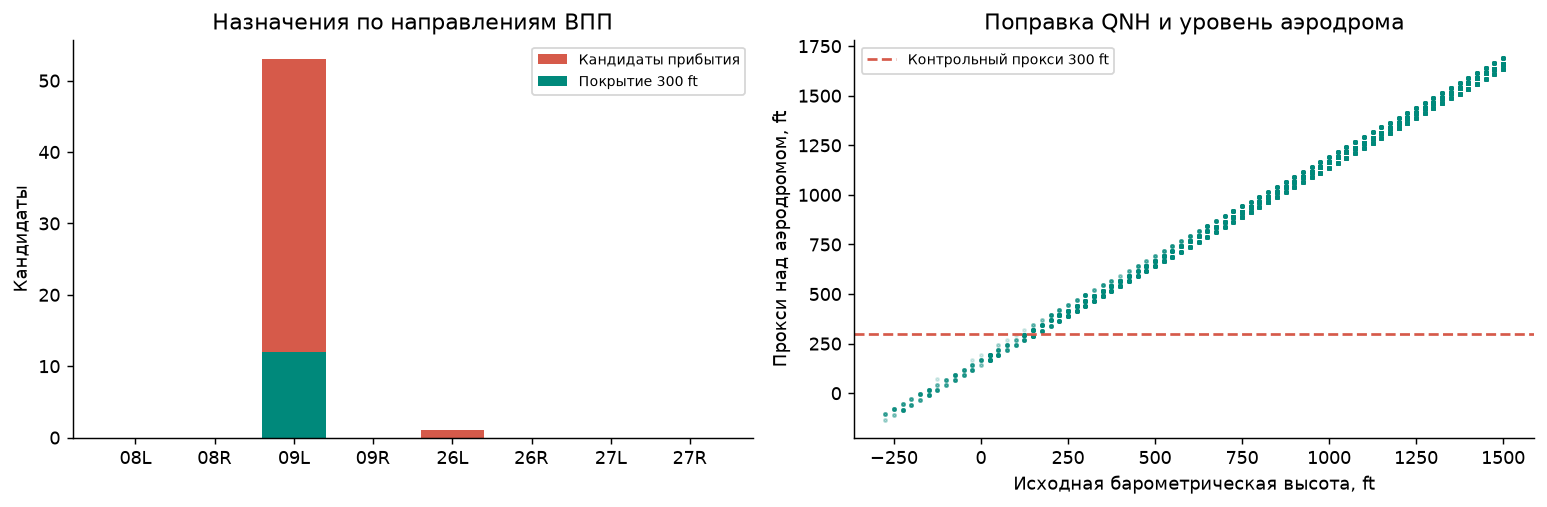

In [5]:
# Сравниваем заранее заданные поисковые коридоры
sensitivity = []
for width in [100, 200, 300]:
    alternative, _ = find_events(enriched, geometry, corridor_m=width)
    arrivals = alternative.loc[alternative.direction.eq('arrival')]
    sensitivity.append({'corridor_m': width, 'arrival_assignments': len(arrivals),
                        'ambiguous_arrivals': int(arrivals.parallel_ambiguity.sum()),
                        'coverage300_candidates': int(arrivals.coverage300_candidate.sum())})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(BASE / 'reports/03_corridor_sensitivity.csv', index=False)
display(sensitivity)
arrivals = events.loc[events.direction.eq('arrival')]
gap_sensitivity = pd.DataFrame([{'max_gap_s': gap,
    'coverage300_candidates': int((arrivals.cross300_observed & arrivals.cross300_gap_s.le(gap)
        & arrivals.precontrol_max_gap_s.le(gap) & arrivals.precontrol_span_s.ge(60)
        & ~arrivals.parallel_ambiguity).sum())} for gap in [10, 15, 30]])
gap_sensitivity.to_csv(BASE / 'reports/03_gap_sensitivity.csv', index=False)
display(gap_sensitivity)

# Отделяем исходную барометрическую высоту от поправки и отметки аэродрома
sample = enriched.loc[~enriched.stale_position & enriched.altitude_ft.between(-500, 1500)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = summary.loc[summary.direction.eq('arrival')].set_index('runway')
labels = sorted(geometry.runway)
axes[0].bar(labels, counts.candidates.reindex(labels, fill_value=0), color=RED, label='Кандидаты прибытия')
axes[0].bar(labels, counts.coverage300.reindex(labels, fill_value=0), color=GREEN, label='Покрытие 300 ft')
axes[0].set(title='Назначения по направлениям ВПП', ylabel='Кандидаты')
axes[0].legend(fontsize=8)
axes[1].scatter(sample.altitude_ft, sample.height_proxy_ft, s=3, alpha=.15, color=GREEN)
axes[1].axhline(300, color=RED, linestyle='--', label='Контрольный прокси 300 ft')
axes[1].set(title='Поправка QNH и уровень аэродрома',
            xlabel='Исходная барометрическая высота, ft', ylabel='Прокси над аэродромом, ft')
axes[1].legend(fontsize=8)
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/03_runway_and_height_coverage.{ext}', bbox_inches='tight')
plt.show()

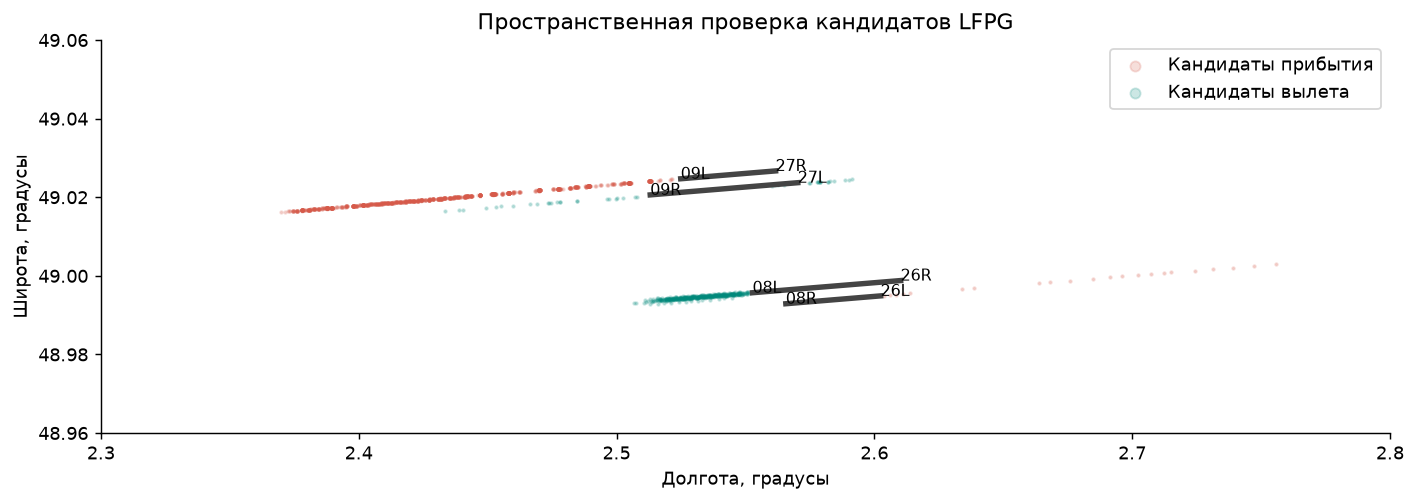

,date,geometry_reference,airport_elevation_ft,arrival_assignments,departure_assignments,coverage300_candidates,suggested_runway_for_pilot,official_historical_validity_verified,actual_received_at_known,glideslope_capture_verified,true_height_verified,goaround_labels_created,interpretation
0,2025-01-15,121faf552580e224617e23867e491f8b5b7bc0f9,392.0,54,38,12,09L,False,False,False,False,False,Геометрические кандидаты и покрытие барометрич...


In [6]:
# Показываем низкие точки найденных прибытий и вылетов относительно ВПП
fig, ax = plt.subplots(figsize=(11, 6))
for direction, color, label in [('arrival', RED, 'Кандидаты прибытия'), ('departure', GREEN, 'Кандидаты вылета')]:
    subset = event_points.loc[event_points.direction.eq(direction) & event_points.height_proxy_ft.le(2000)]
    ax.scatter(subset.lon, subset.lat, s=2, alpha=.2, color=color, label=label)
for runway in runways.itertuples(index=False):
    ax.plot([runway.le_longitude_deg, runway.he_longitude_deg],
            [runway.le_latitude_deg, runway.he_latitude_deg], color='#444444', linewidth=3)
    ax.text(runway.le_longitude_deg, runway.le_latitude_deg, runway.le_ident, fontsize=9)
    ax.text(runway.he_longitude_deg, runway.he_latitude_deg, runway.he_ident, fontsize=9)
ax.set(title='Пространственная проверка кандидатов LFPG', xlabel='Долгота, градусы', ylabel='Широта, градусы')
ax.set_xlim(2.3, 2.8)
ax.set_ylim(48.96, 49.06)
ax.set_aspect(1 / np.cos(np.deg2rad(49)))
ax.legend(markerscale=4)
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/03_candidate_geometry.{ext}', bbox_inches='tight')
plt.show()

# Выбираем направление по диагностическому покрытию с фиксированным правилом
ranking = summary.loc[summary.direction.eq('arrival')].sort_values(
    ['coverage300', 'candidates', 'runway'], ascending=[False, False, True])
suggested = ranking.runway.iloc[0]
result = {'date': '2025-01-15', 'geometry_reference': source['ourairports_reference'],
    'airport_elevation_ft': float(airport.elevation_ft),
    'arrival_assignments': int(events.direction.eq('arrival').sum()),
    'departure_assignments': int(events.direction.eq('departure').sum()),
    'coverage300_candidates': int(events.coverage300_candidate.sum()),
    'suggested_runway_for_pilot': suggested,
    'official_historical_validity_verified': False,
    'actual_received_at_known': False, 'glideslope_capture_verified': False,
    'true_height_verified': False, 'goaround_labels_created': False,
    'interpretation': 'Геометрические кандидаты и покрытие барометрического прокси; не подтвержденные эксплуатационные события'}
(BASE / 'reports/03_research_result.json').write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([result]))

## Проверка отдельных профилей

Показаны три случая с заранее заданными правилами выбора: покрытый кандидат с наибольшим временем до контрольной границы, покрытый кандидат с наибольшим допустимым разрывом и отклоненный кандидат с наибольшим разрывом до границы. Если выбор совпадает, используется следующий случай. Это диагностическая проверка, а не случайная или репрезентативная выборка.

На рисунке исходная высота минус отметка аэродрома сопоставлена с прокси после поправки QNH; отдельно видны интервалы наблюдений. Линии соединяют измерения для просмотра и не заполняют пропуски в данных.

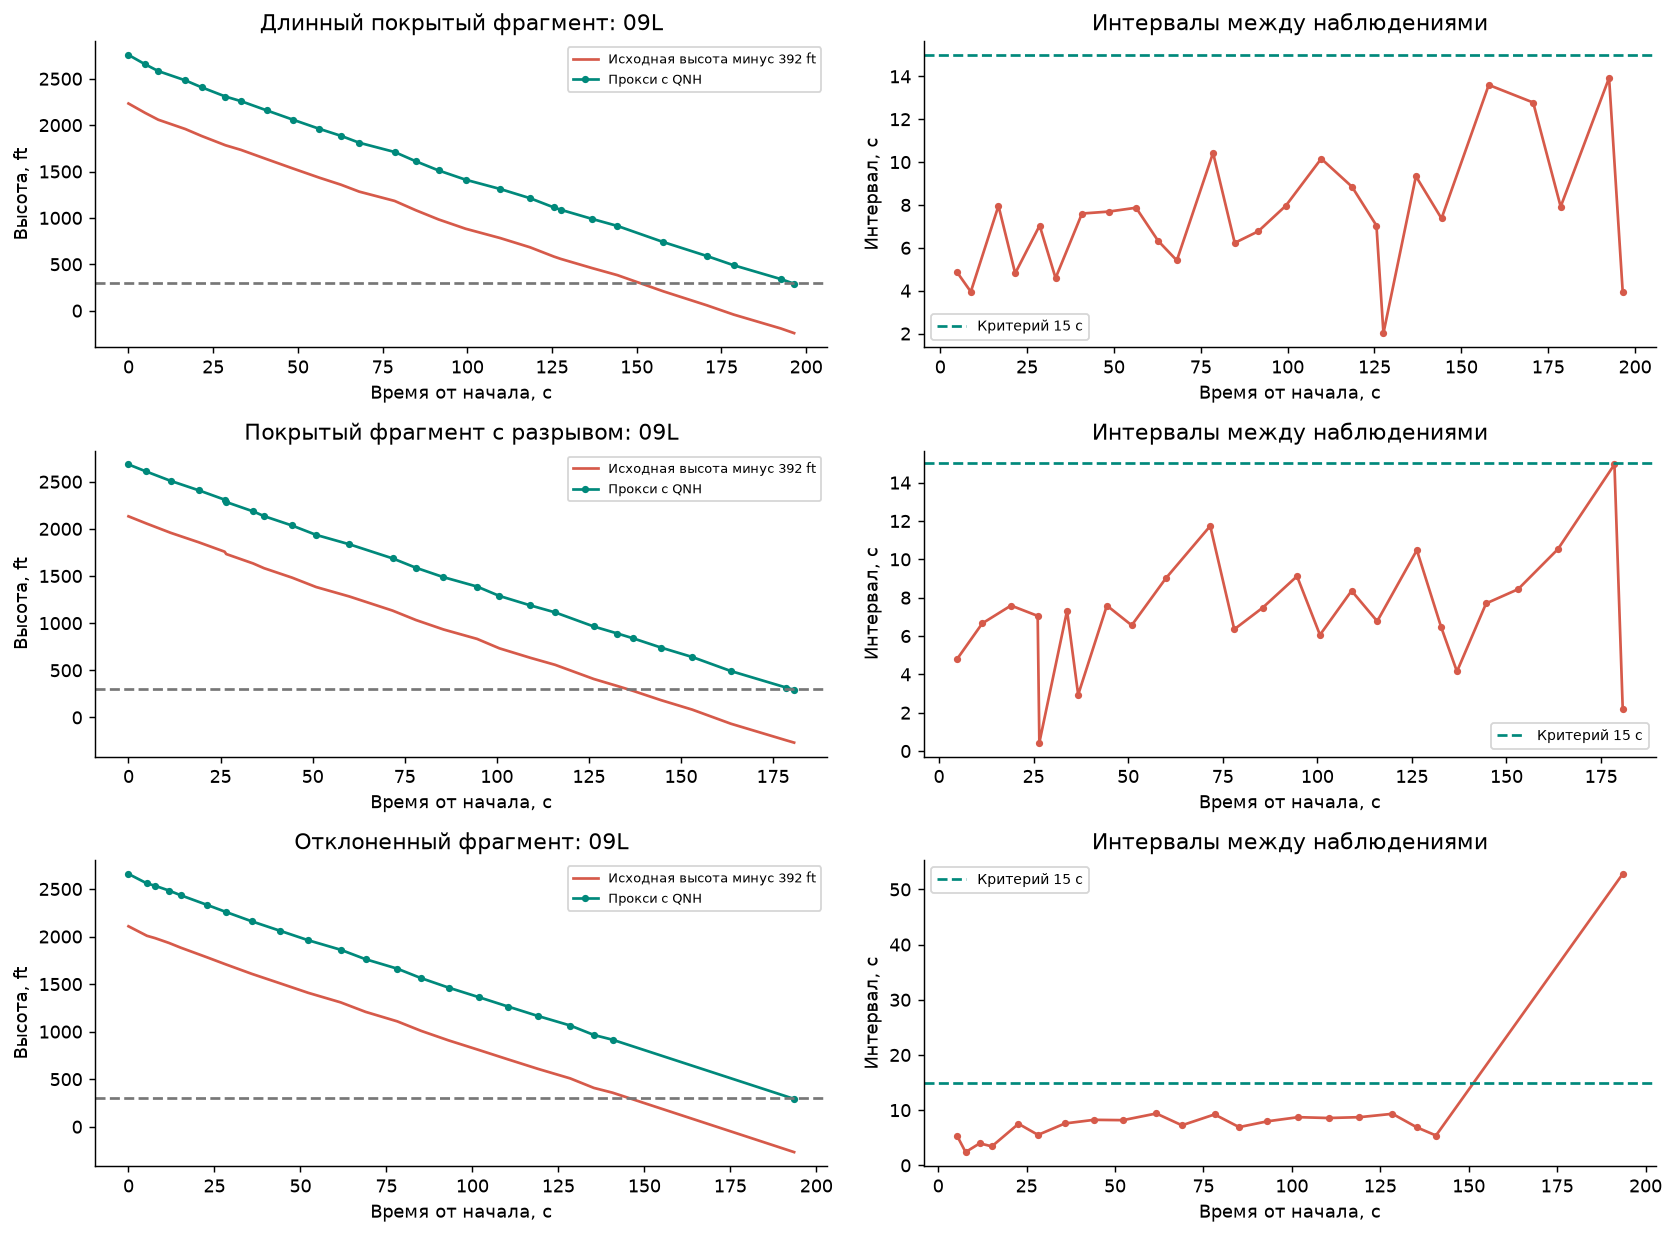

Проверки итогов и критериев покрытия пройдены


In [7]:
# Выбираем разные профили по описанным правилам
passed = arrivals.loc[arrivals.coverage300_candidate]
failed = arrivals.loc[~arrivals.coverage300_candidate]
selection = []
for pool, field, label in [(passed, 'precontrol_span_s', 'Длинный покрытый фрагмент'),
                           (passed, 'precontrol_max_gap_s', 'Покрытый фрагмент с разрывом'),
                           (failed, 'precontrol_max_gap_s', 'Отклоненный фрагмент')]:
    available = pool.loc[~pool.event_id.isin([item[0].event_id for item in selection])]
    if len(available):
        selection.append((available.sort_values(field, ascending=False).iloc[0], label))
fig, axes = plt.subplots(len(selection), 2, figsize=(13, 3.2 * len(selection)), squeeze=False)
selected_rows = []
for row_index, (event, label) in enumerate(selection):
    group = event_points.loc[event_points.event_id.eq(event.event_id)].sort_values('time')
    elapsed = group.time - group.time.iloc[0]
    axes[row_index, 0].plot(elapsed, group.raw_minus_airport_ft, color=RED, label='Исходная высота минус 392 ft')
    axes[row_index, 0].plot(elapsed, group.height_proxy_ft, color=GREEN, marker='.', label='Прокси с QNH')
    axes[row_index, 0].axhline(300, color='#777777', linestyle='--')
    axes[row_index, 0].set(title=f'{label}: {event.runway}', ylabel='Высота, ft', xlabel='Время от начала, с')
    axes[row_index, 0].legend(fontsize=7)
    axes[row_index, 1].plot(elapsed, group.time.diff(), color=RED, marker='.')
    axes[row_index, 1].axhline(15, color=GREEN, linestyle='--', label='Критерий 15 с')
    axes[row_index, 1].set(title='Интервалы между наблюдениями', ylabel='Интервал, с', xlabel='Время от начала, с')
    axes[row_index, 1].legend(fontsize=8)
    selected_rows.append({'event_id': event.event_id, 'runway': event.runway,
                          'selection_rule': label, 'coverage300': bool(event.coverage300_candidate),
                          'precontrol_max_gap_s': float(event.precontrol_max_gap_s)})
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/03_profile_review.{ext}', bbox_inches='tight')
plt.show()
pd.DataFrame(selected_rows).to_csv(BASE / 'reports/03_profile_review.csv', index=False)

# Проверяем согласованность итогов и обязательных критериев покрытия
assert events.event_id.is_unique
assert int(summary.candidates.sum()) == len(events)
assert int(summary.coverage300.sum()) == int(events.coverage300_candidate.sum())
assert passed.cross300_gap_s.le(15).all() and passed.precontrol_max_gap_s.le(15).all()
assert passed.precontrol_span_s.ge(60).all() and not passed.parallel_ambiguity.any()
print('Проверки итогов и критериев покрытия пройдены')

## Вывод и границы результата

В пилоте есть последовательные траектории, согласующиеся с геометрией прибытия и вылета LFPG. Диагностическое покрытие 300 ft проверяется отдельно от простой близости к аэропорту. Направление для следующего пилота предлагается по числу таких кандидатов на один день; это предварительный выбор, который требует проверки отдельных профилей и других дат.

Для базового коридора получены 54 назначения прибытия и 38 вылета. Прибытия: 53 кандидата 09L и один 26L. Критерии покрытия 300 ft проходят 12 кандидатов, все 09L. При ширине 100/200/300 м результат одинаков; при максимальном разрыве 10/15/30 с число покрытых кандидатов равно 0/12/37. Следовательно, доступность наблюдений существенно зависит от выбранного требования к разрывам. Это не 54 подтвержденные посадки и не оценка полного суточного покрытия аэропорта.

Исходная отрицательная барометрическая высота не является доказанной ошибкой: давление на дату пилота выше стандартного, и поправка QNH существенно меняет высотную интерпретацию. Временная доступность METAR остается условной, температурные и приборные ошибки не устранены.

Следующий шаг – ручная проверка нескольких кандидатов выбранной ВПП с профилями, разрывами и источниками. Затем уточняются геометрический прокси начала мониторинга и протокол поиска уходов, включая события, которые не проходят текущие правила завершенного низкого прибытия. Обучение и эксплуатационные рекомендации на этом этапе не выполняются.